### Задача: на различных тестовых данных  из библиотеки sklearn проверить как меняется f1_scrore, roc_auc_score при использовании логистической регрессии и SVM

In [1]:
import numpy as np

import matplotlib.pyplot as plt
# print(plt.style.available)
plt.style.use("seaborn-v0_8")

from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.datasets import make_circles, make_classification, make_moons
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, roc_auc_score

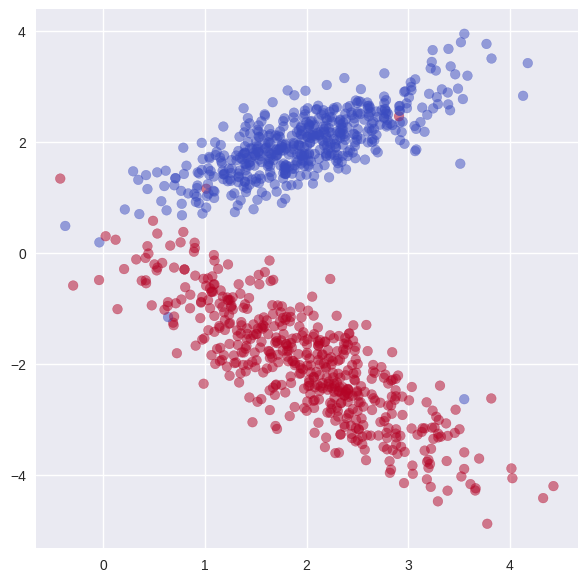

In [2]:
X_blobs, y_blobs = make_classification(
    n_samples=1000,
    n_features=2,
    n_informative=2,
    n_redundant=0,
    n_clusters_per_class=1,
    class_sep=2,
    random_state=1
)

plt.figure(figsize=(7,7))
plt.scatter(
    X_blobs[:, 0], X_blobs[:, 1],
    c=y_blobs,
    cmap='coolwarm',
    alpha=0.5
)

plt.show()

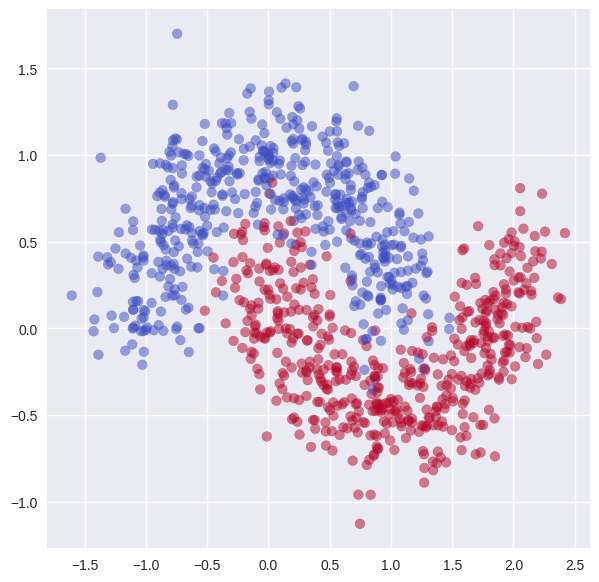

In [3]:
X_moons, y_moons = make_moons(n_samples=1000, noise=0.2, random_state=1)

plt.figure(figsize=(7,7))
plt.scatter(
    X_moons[:, 0], X_moons[:, 1],
    c=y_moons,
    cmap='coolwarm',
    alpha=0.5
)

plt.show()

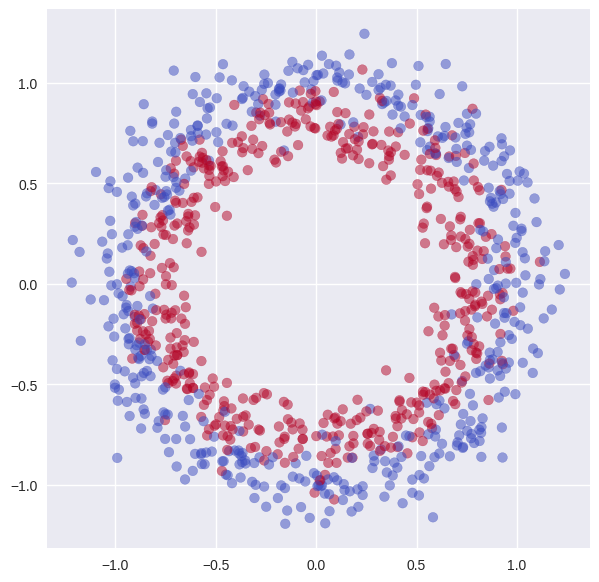

In [4]:
X_circles, y_circles = make_circles(n_samples=1000, noise=0.1, random_state=1)

plt.figure(figsize=(7,7))
plt.scatter(
    X_circles[:, 0], X_circles[:, 1],
    c=y_circles,
    cmap='coolwarm',
    alpha=0.5
)

plt.show()

### Классификация методом опорных векторов

In [21]:
def draw_svm_boundary(clf, X, y):
    DecisionBoundaryDisplay.from_estimator(
        clf, X, plot_method='contour', levels=[-1, 0, 1]
    )
    plt.scatter(
        X[:, 0], X[:, 1],
        c=y,
        cmap='coolwarm',
        alpha=0.5
    )
    plt.scatter(
        clf.support_vectors_[:, 0],
        clf.support_vectors_[:, 1],
        s=100, 
        facecolors="none",
        edgecolors="black",
        linewidths=1,
    )
    plt.xlim([X[:, 0].min(), X[:, 0].max()])
    plt.ylim([X[:, 1].min(), X[:, 1].max()])
    plt.show()
    

In [22]:
clf = SVC(C=1000, kernel="linear", probability=True)

In [23]:
datasets = [
    (X_blobs, y_blobs),
    (X_moons, y_moons),
    (X_circles, y_circles)
]

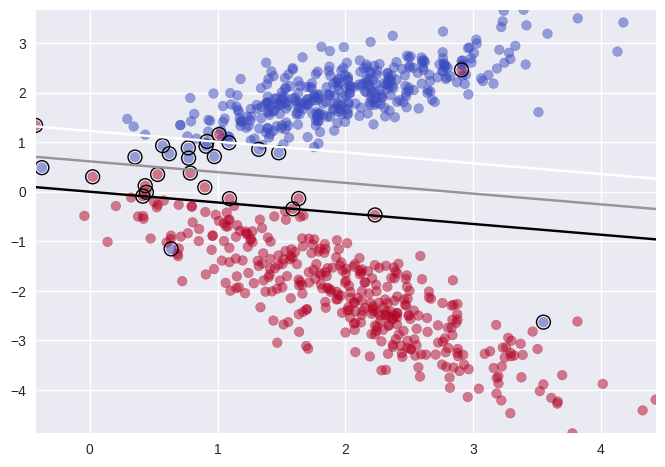

ROC AUC: 0.999552, f1 SCORE: 0.992


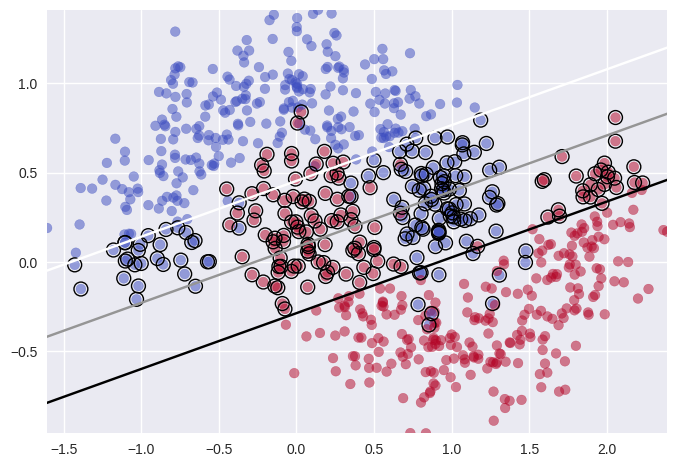

ROC AUC: 0.9564353898391953, f1 SCORE: 0.8992248062015504


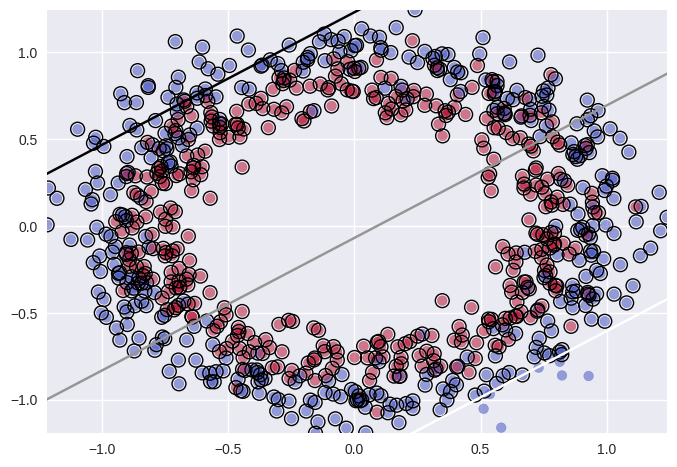

ROC AUC: 0.5152155807546928, f1 SCORE: 0.5190839694656488


In [24]:
for dataset in datasets:
    X_train, X_test, y_train, y_test = train_test_split(dataset[0], dataset[1], random_state=0)
    clf.fit(X_train, y_train)
    draw_svm_boundary(clf, X_train, y_train)
    preds = clf.predict(X_test)
    f1 = f1_score(y_test, preds)
    auc = roc_auc_score(y_test, clf.predict_proba(X_test)[:, 1])
    print(f'ROC AUC: {auc}, f1 SCORE: {f1}')

#### Изменим ядро  на 'rbf'

In [25]:
clf = SVC(C=1000, kernel="rbf", probability=True)

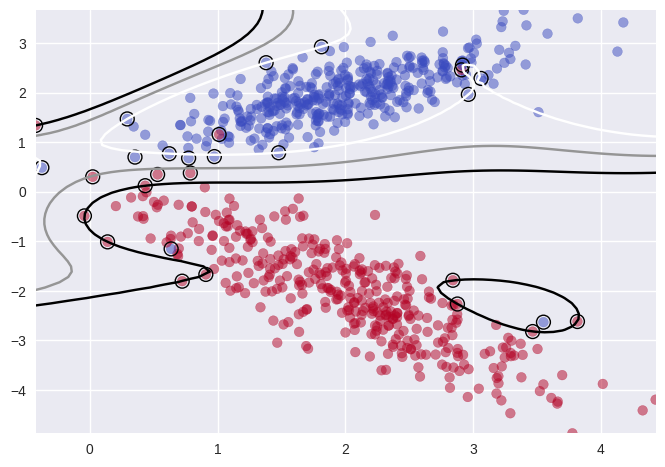

ROC AUC: 0.999936, f1 SCORE: 0.992


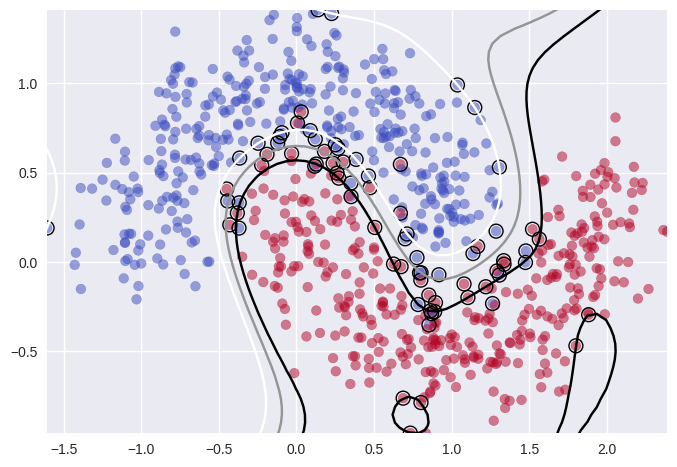

ROC AUC: 0.9941700301108335, f1 SCORE: 0.9769230769230769


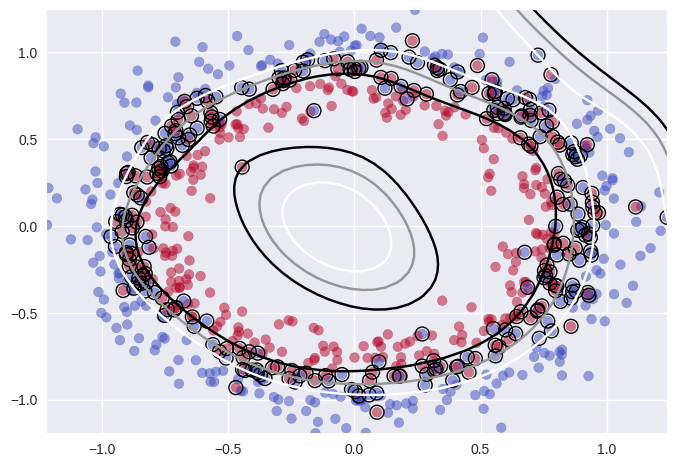

ROC AUC: 0.924274457044013, f1 SCORE: 0.8582995951417004


In [26]:
for dataset in datasets:
    X_train, X_test, y_train, y_test = train_test_split(dataset[0], dataset[1], random_state=0)
    clf.fit(X_train, y_train)
    draw_svm_boundary(clf, X_train, y_train)
    preds = clf.predict(X_test)
    f1 = f1_score(y_test, preds)
    auc = roc_auc_score(y_test, clf.predict_proba(X_test)[:, 1])
    print(f'ROC AUC: {auc}, f1 SCORE: {f1}')

### Метод логистической регрессии

In [27]:
def draw_logreg_boundary(clf, X, y):
    DecisionBoundaryDisplay.from_estimator(
        clf, X, plot_method='contour', levels=[0]
    )
    plt.scatter(
        X[:, 0], X[:, 1],
        c=y,
        cmap='coolwarm',
        alpha=0.5
    )
    
    plt.xlim([X[:, 0].min(), X[:, 0].max()])
    plt.ylim([X[:, 1].min(), X[:, 1].max()])
    plt.show()
    

In [28]:
clf = LogisticRegression(penalty=None)

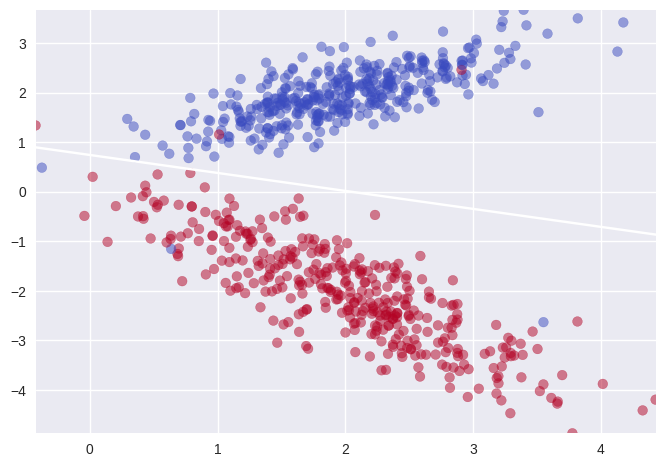

ROC AUC: 0.999488, f1 SCORE: 0.992


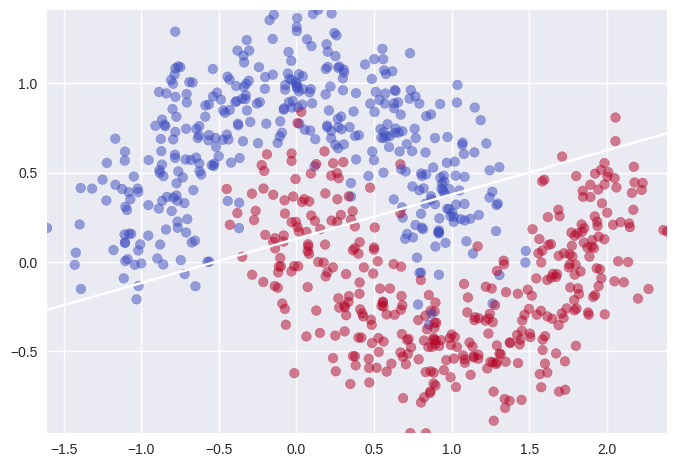

ROC AUC: 0.958165161124992, f1 SCORE: 0.9027237354085603


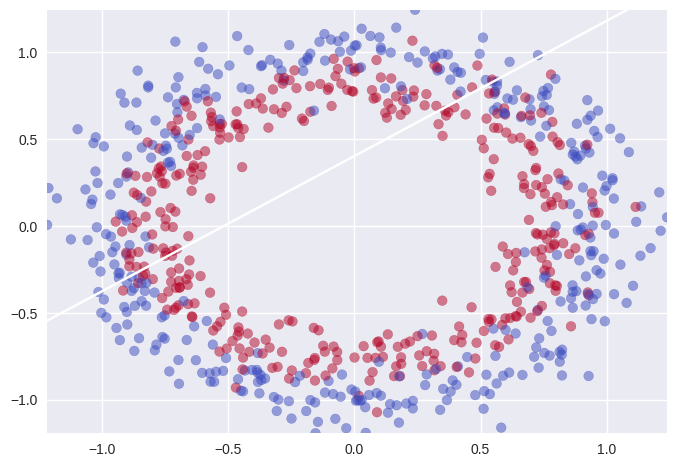

ROC AUC: 0.485937600102505, f1 SCORE: 0.41964285714285715


In [29]:
for dataset in datasets:
    X_train, X_test, y_train, y_test = train_test_split(dataset[0], dataset[1], random_state=0)
    clf.fit(X_train, y_train)
    draw_logreg_boundary(clf, X_train, y_train)
    preds = clf.predict(X_test)
    f1 = f1_score(y_test, preds)
    auc = roc_auc_score(y_test, clf.predict_proba(X_test)[:, 1])
    print(f'ROC AUC: {auc}, f1 SCORE: {f1}')

##### Чтобы логистич регрессия в 3-м случае с кольцами показала результат так как она все же является линейным классификатором то необхлодимо добавить новый третий признак чтобы был результат

In [41]:
X, y = X_circles, y_circles

X_extended = np.concatenate([X, (X[:, 0] ** 2 + X[:, 1] ** 2).reshape(-1, 1)], axis=1)

In [42]:
X_train, X_test, y_train, y_test = train_test_split(X_extended, y, random_state=0)
clf.fit(X_train, y_train)

preds = clf.predict(X_test)
f1 = f1_score(y_test, preds)
auc = roc_auc_score(y_test, clf.predict_proba(X_test)[:, 1])
print(f'ROC AUC: {auc}, f1 SCORE: {f1}')

ROC AUC: 0.9338202319174835, f1 SCORE: 0.8536585365853658
